# Traditional computer vision

Publication formatting replaces private absolute data paths with environment variables. Private paths in saved warnings are redacted. Original cells and recorded experiment outputs follow.

- `RGBD_DATASET_ROOT` defaults to `rgbd-dataset-crop`.

This supplied notebook preserves the 70:30 sweep and its recall follow-up. The final 80:20 sweep is documented in the coursework report and in the separate results table.

In [1]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
from sklearn.cluster import MiniBatchKMeans
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix, classification_report, ConfusionMatrixDisplay
import seaborn as sns
import random
import time
from sklearn.decomposition import PCA
# Step 1: Paths and data structures
# Path
DATASET_PATH = os.environ.get("RGBD_DATASET_ROOT", "rgbd-dataset-crop")

# Collect_images_paths_and_labels
def collect_all_image_paths_and_labels(dataset_path):
    image_paths = []
    labels = []
    label_map = {}
    label_id = 0
    stats = []

    for cat in sorted(os.listdir(dataset_path)):
        cat_path = os.path.join(dataset_path, cat)
        if os.path.isdir(cat_path):
            for sub in sorted(os.listdir(cat_path)):
                sub_path = os.path.join(cat_path, sub)
                if os.path.isdir(sub_path):
                    count = 0
                    label_map[label_id] = f"{cat}/{sub}"
                    for fname in os.listdir(sub_path):
                        if fname.endswith("_crop.png"):
                            img_path = os.path.join(sub_path, fname)
                            image_paths.append(img_path)
                            labels.append(label_id)
                            count += 1
                    stats.append({
                        "Main Category": cat,
                        "Subcategory": sub,
                        "Image Count": count
                    })
                    label_id += 1
    return image_paths, labels, label_map, stats

image_paths, labels, label_map, stats = collect_all_image_paths_and_labels(DATASET_PATH)

# Creat DataFrame
df_detail = pd.DataFrame(stats)
df_detail.sort_values(by=["Main Category", "Subcategory"], inplace=True)

# Constructing a main category-subcategory statistics table
df_summary = df_detail.groupby("Main Category").agg({
    "Subcategory": "count",
    "Image Count": "sum"
}).rename(columns={"Subcategory": "Subcategory Count"}).reset_index()

# Summary Table
summary_df = pd.DataFrame({
    "Statistic": ["Main Category Count", "Subcategory Count", "Total Crop Images"],
    "Value": [df_summary.shape[0], df_detail.shape[0], len(image_paths)]
})

# Display
print("Summary of Image Dataset:")
display(summary_df)

print("\nTop 10 Main Categories:")
display(df_summary.head(10))

print("\nTop 10 Detailed Subcategories with Image Counts:")
display(df_detail.head(10))

# Export to Excel
with pd.ExcelWriter("image_category_statistics_2.xlsx") as writer:
    summary_df.to_excel(writer, sheet_name="Summary", index=False)
    df_summary.to_excel(writer, sheet_name="Main Category Stats", index=False)
    df_detail.to_excel(writer, sheet_name="Detailed Category Image Count", index=False)
print (" successful")

Summary of Image Dataset:


,Statistic,Value
0,Main Category Count,51
1,Subcategory Count,300
2,Total Crop Images,207920



Top 10 Main Categories:


,Main Category,Subcategory Count,Image Count
0,apple,5,3098
1,ball,7,5561
2,banana,4,2826
3,bell_pepper,6,3784
4,binder,3,2129
5,bowl,6,3884
6,calculator,5,2934
7,camera,3,1725
8,cap,4,2551
9,cell_phone,5,2712



Top 10 Detailed Subcategories with Image Counts:


,Main Category,Subcategory,Image Count
0,apple,apple_1,607
1,apple,apple_2,622
2,apple,apple_3,607
3,apple,apple_4,633
4,apple,apple_5,629
5,ball,ball_1,820
6,ball,ball_2,783
7,ball,ball_3,809
8,ball,ball_4,800
9,ball,ball_5,794


 successful


In [11]:
# Classification with Bow + SVM (Sampled 200 per category)
# SIFT parameter grid 
sift_param_grid = [
    # Lightweight configurations (nfeatures = 200)
    {"nfeatures": 200, "contrastThreshold": 0.04, "edgeThreshold": 10, "sigma": 1.6},  # Excellent result in keypoint count
    {"nfeatures": 200, "contrastThreshold": 0.03, "edgeThreshold": 10, "sigma": 1.6},  # Stable baseline with low complexity

    # Medium-capacity configurations
    {"nfeatures": 300, "contrastThreshold": 0.03, "edgeThreshold": 10, "sigma": 1.6},  # Balanced configuration, widely used
    {"nfeatures": 300, "contrastThreshold": 0.05, "edgeThreshold": 10, "sigma": 1.6},  # Slightly more selective, for contrast comparison

    # High-capacity configurations
    {"nfeatures": 400, "contrastThreshold": 0.03, "edgeThreshold": 10, "sigma": 1.6},  # Good trade-off between performance and density
    {"nfeatures": 400, "contrastThreshold": 0.02, "edgeThreshold": 10, "sigma": 1.6},  # High-sensitivity version of above

    # Extended expressive capacity
    {"nfeatures": 500, "contrastThreshold": 0.03, "edgeThreshold": 10, "sigma": 1.6},  # Testing BoW saturation range
    {"nfeatures": 600, "contrastThreshold": 0.02, "edgeThreshold": 10, "sigma": 1.6},  # Most expressive setting from previous experiments
]

# generate unique ID for each SIFT parameter setting 
def generate_param_id(params):
    return f"nf{params['nfeatures']}_ct{params['contrastThreshold']}_et{params['edgeThreshold']}_sg{params['sigma']}"

# sample up to N images per category
def sample_images_by_category(image_paths, labels, label_map, max_per_class=200):
    label_to_images = {}
    for path, label in zip(image_paths, labels):
        label_to_images.setdefault(label, []).append(path)

    sampled_paths = []
    sampled_labels = []
    for label, paths in label_to_images.items():
        sampled = random.sample(paths, min(max_per_class, len(paths)))
        sampled_paths.extend(sampled)
        sampled_labels.extend([label] * len(sampled))
    return sampled_paths, sampled_labels

In [13]:
# Extract SIFT descriptors and compute keypoint stats 
def extract_sift_descriptors_and_stats(image_paths, sift_params):
    sift = cv2.SIFT_create(**sift_params)
    descriptors = []
    keypoint_counts = []

    for path in tqdm(image_paths, desc=f"Extracting SIFT: {sift_params}"):
        img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
        if img is None:
            descriptors.append(np.array([]))
            keypoint_counts.append(0)
            continue
        _, des = sift.detectAndCompute(img, None)
        des = des if des is not None else np.array([])
        descriptors.append(des)
        keypoint_counts.append(len(des))

    mean_kp = np.mean(keypoint_counts)
    std_kp = np.std(keypoint_counts)
    return descriptors, mean_kp, std_kp

In [15]:
# Compute BoW histograms for each image 
def compute_bow_histograms(descriptors, k):
    all_des = np.vstack([d for d in descriptors if d.shape[0] > 0])
    kmeans = MiniBatchKMeans(n_clusters=k, batch_size=1000, random_state=42)
    kmeans.fit(all_des)

    histograms = []
    for des in descriptors:
        if des.shape[0] > 0:
            pred = kmeans.predict(des)
            hist, _ = np.histogram(pred, bins=np.arange(k+1))
        else:
            hist = np.zeros(k)
        histograms.append(hist)
    return np.array(histograms)

In [17]:
# Load image paths, labels and label map
# NOTE: You must define this function separately based on your folder structure.
# Example: image_paths, labels, label_map, _ = collect_all_image_paths_and_labels(DATASET_PATH)
#  Sample dataset 
sampled_image_paths, sampled_labels = sample_images_by_category(image_paths, labels, label_map, max_per_class=200)
# Evaluate average keypoints per configuration 
keypoint_results = []
for params in sift_param_grid:
    descriptors, avg_kp, std_kp = extract_sift_descriptors_and_stats(sampled_image_paths, params)
    keypoint_results.append({
        "nfeatures": params["nfeatures"],
        "contrastThreshold": params["contrastThreshold"],
        "edgeThreshold": params["edgeThreshold"],
        "sigma": params["sigma"],
        "avg_keypoints": avg_kp,
        "std_keypoints": std_kp
    })

Extracting SIFT: {'nfeatures': 200, 'contrastThreshold': 0.04, 'edgeThreshold': 10, 'sigma': 1.6}: 100%|█| 60000/60000 
Extracting SIFT: {'nfeatures': 200, 'contrastThreshold': 0.03, 'edgeThreshold': 10, 'sigma': 1.6}: 100%|█| 60000/60000 
Extracting SIFT: {'nfeatures': 300, 'contrastThreshold': 0.03, 'edgeThreshold': 10, 'sigma': 1.6}: 100%|█| 60000/60000 
Extracting SIFT: {'nfeatures': 300, 'contrastThreshold': 0.05, 'edgeThreshold': 10, 'sigma': 1.6}: 100%|█| 60000/60000 
Extracting SIFT: {'nfeatures': 400, 'contrastThreshold': 0.03, 'edgeThreshold': 10, 'sigma': 1.6}: 100%|█| 60000/60000 
Extracting SIFT: {'nfeatures': 400, 'contrastThreshold': 0.02, 'edgeThreshold': 10, 'sigma': 1.6}: 100%|█| 60000/60000 
Extracting SIFT: {'nfeatures': 500, 'contrastThreshold': 0.03, 'edgeThreshold': 10, 'sigma': 1.6}: 100%|█| 60000/60000 
Extracting SIFT: {'nfeatures': 600, 'contrastThreshold': 0.02, 'edgeThreshold': 10, 'sigma': 1.6}: 100%|█| 60000/60000 


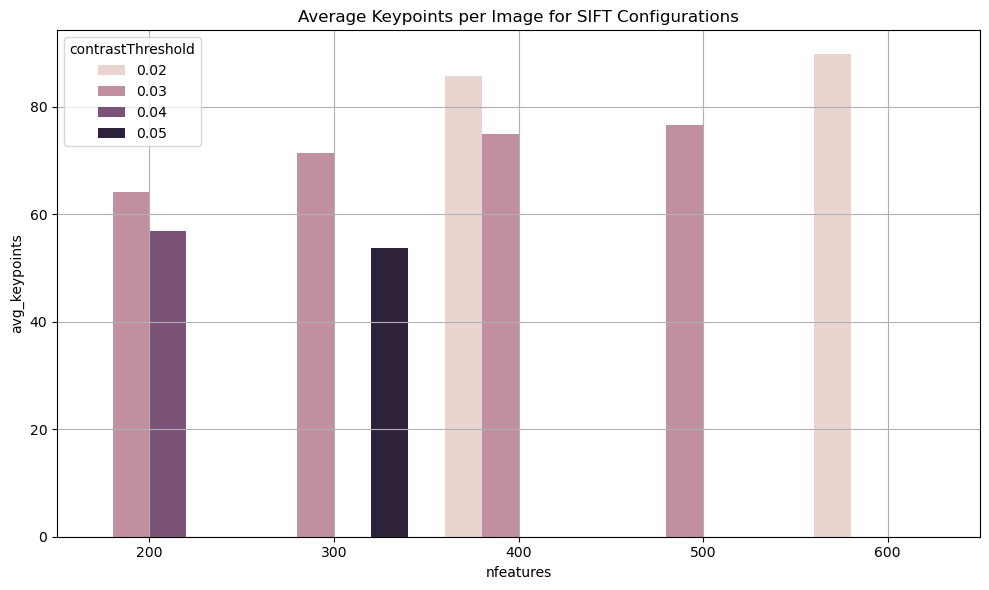

In [18]:
#  Visualize keypoint statistics 
key_df = pd.DataFrame(keypoint_results)
plt.figure(figsize=(10, 6))
sns.barplot(data=key_df, x="nfeatures", y="avg_keypoints", hue="contrastThreshold")
plt.title("Average Keypoints per Image for SIFT Configurations")
plt.grid(True)
plt.tight_layout()
plt.show()

In [19]:
# Full pipeline: BoW + PCA + SVM for each SIFT config 
results = []
for i, params in enumerate(sift_param_grid):
    print(f"\n▶ Running SIFT config {i+1}/{len(sift_param_grid)}: {params}")
    group_start = time.time()
    param_id = generate_param_id(params)

    # 1: Feature extraction
    descriptors, avg_kp, _ = extract_sift_descriptors_and_stats(sampled_image_paths, params)

    for k in [100, 300, 500]:
        print(f"  ▶ BoW vocabulary size k = {k}")
        X = compute_bow_histograms(descriptors, k)

        # 2 (optional): PCA dimensionality reduction if k >= 300
        if k >= 300:
            print("    ▶ Applying PCA...")
            pca_bow = PCA(n_components=0.95, random_state=42)
            X = pca_bow.fit_transform(X)
            print(f"    ▶ PCA reduced to {X.shape[1]} dimensions")

        y = np.array(sampled_labels)
        X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify=y, random_state=42)

        # 3: Train and evaluate SVM
        for c in [0.1, 1.0, 10.0]:
            print(f"    ▶ Training SVM with C = {c}")
            t1 = time.time()
            clf = SVC(kernel='linear', C=c, random_state=42)
            clf.fit(X_train, y_train)
            y_pred = clf.predict(X_test)
            acc = accuracy_score(y_test, y_pred)
            print(f"  Accuracy = {acc:.4f} ({(time.time() - t1):.1f}s)")

            results.append({
                "param_id": param_id,
                "nfeatures": params["nfeatures"],
                "contrastThreshold": params["contrastThreshold"],
                "edgeThreshold": params["edgeThreshold"],
                "sigma": params["sigma"],
                "avg_keypoints": avg_kp,
                "bow_k": k,
                "svm_C": c,
                "accuracy": acc
            })

    print(f"Finished config {i+1} in {(time.time() - group_start)/60:.2f} minutes")


▶ Running SIFT config 1/8: {'nfeatures': 200, 'contrastThreshold': 0.04, 'edgeThreshold': 10, 'sigma': 1.6}


Extracting SIFT: {'nfeatures': 200, 'contrastThreshold': 0.04, 'edgeThreshold': 10, 'sigma': 1.6}: 100%|█| 60000/60000 


  ▶ BoW vocabulary size k = 100


[local path]/_kmeans.py:1955: UserWarning: MiniBatchKMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can prevent it by setting batch_size >= 3584 or by setting the environment variable OMP_NUM_THREADS=4
  warnings.warn(


    ▶ Training SVM with C = 0.1
  Accuracy = 0.6579 (165.1s)
    ▶ Training SVM with C = 1.0
  Accuracy = 0.6588 (164.4s)
    ▶ Training SVM with C = 10.0
  Accuracy = 0.6521 (170.5s)
  ▶ BoW vocabulary size k = 300


[local path]/_kmeans.py:1955: UserWarning: MiniBatchKMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can prevent it by setting batch_size >= 3584 or by setting the environment variable OMP_NUM_THREADS=4
  warnings.warn(


... (55 outputs left out)

[local path]/_kmeans.py:1955: UserWarning: MiniBatchKMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can prevent it by setting batch_size >= 3584 or by setting the environment variable OMP_NUM_THREADS=4
  warnings.warn(


    ▶ Applying PCA...
    ▶ PCA reduced to 228 dimensions
    ▶ Training SVM with C = 0.1
  Accuracy = 0.7778 (215.1s)
    ▶ Training SVM with C = 1.0
  Accuracy = 0.7746 (214.9s)
    ▶ Training SVM with C = 10.0
  Accuracy = 0.7719 (216.2s)
  ▶ BoW vocabulary size k = 500


[local path]/_kmeans.py:1955: UserWarning: MiniBatchKMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can prevent it by setting batch_size >= 3584 or by setting the environment variable OMP_NUM_THREADS=4
  warnings.warn(


    ▶ Applying PCA...
    ▶ PCA reduced to 392 dimensions
    ▶ Training SVM with C = 0.1
  Accuracy = 0.8212 (272.7s)
    ▶ Training SVM with C = 1.0
  Accuracy = 0.8194 (272.3s)
    ▶ Training SVM with C = 10.0
  Accuracy = 0.8154 (271.2s)
Finished config 8 in 39.22 minutes


In [20]:
# Save final results 
df_results = pd.DataFrame(results)
df_results.to_csv("sift_bow_svm_results_sample200_2.csv", index=False)
print("Results saved to sift_bow_svm_results_sample200_2.csv")

Results saved to sift_bow_svm_results_sample200_2.csv


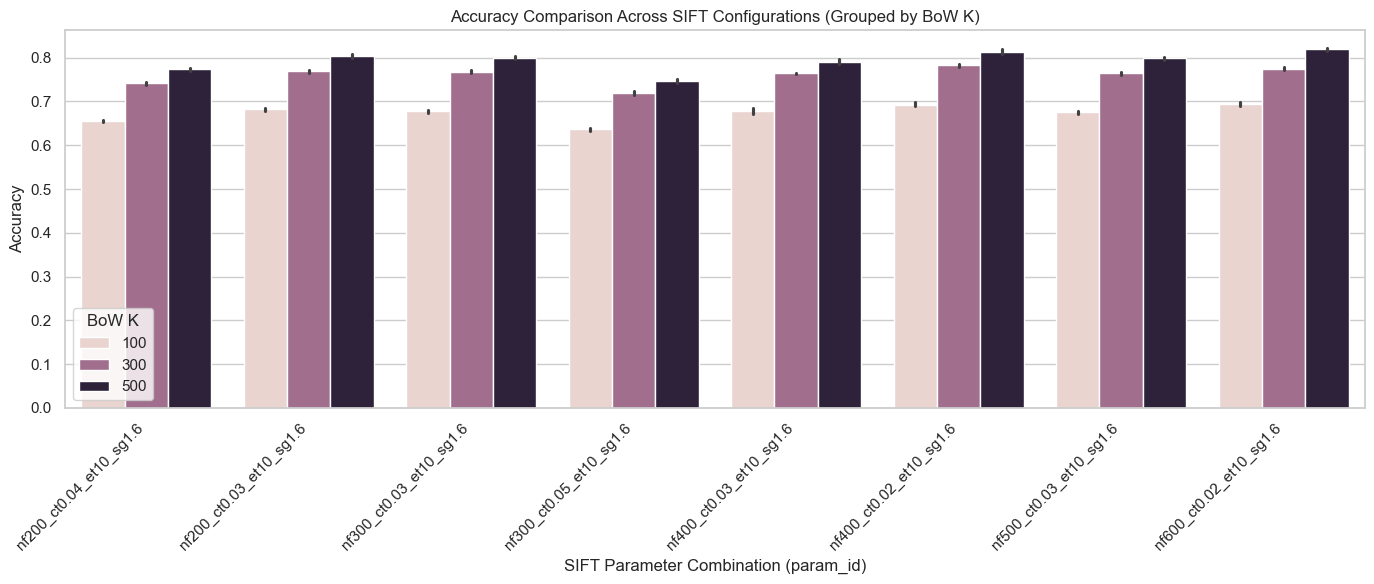

In [21]:
# Load experiment results
df = pd.read_csv("sift_bow_svm_results_sample200_2.csv")
sns.set(style="whitegrid")

# Plot 1: Accuracy by param_id and BoW K
plt.figure(figsize=(14, 6))
sns.barplot(data=df, x="param_id", y="accuracy", hue="bow_k")
plt.title("Accuracy Comparison Across SIFT Configurations (Grouped by BoW K)")
plt.xticks(rotation=45, ha='right')
plt.xlabel("SIFT Parameter Combination (param_id)")
plt.ylabel("Accuracy")
plt.legend(title="BoW K")
plt.tight_layout()
plt.savefig("figure_1_accuracy_by_paramid_bowk_2.png")
plt.show()

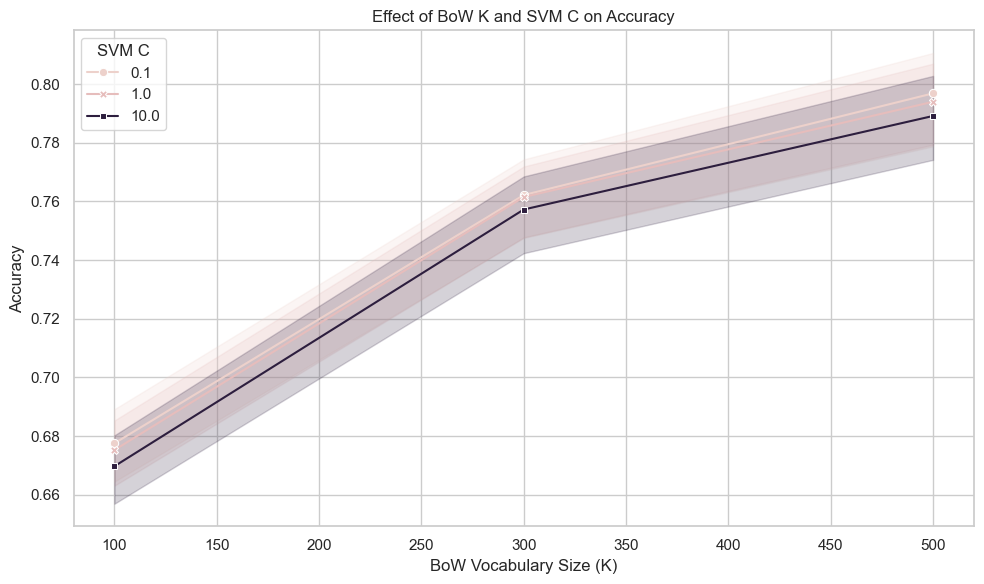

In [22]:
# Plot 2: Accuracy vs BoW K and SVM C
plt.figure(figsize=(10, 6))
sns.lineplot(data=df, x="bow_k", y="accuracy", hue="svm_C", style="svm_C", markers=True, dashes=False)
plt.title("Effect of BoW K and SVM C on Accuracy")
plt.xlabel("BoW Vocabulary Size (K)")
plt.ylabel("Accuracy")
plt.legend(title="SVM C")
plt.tight_layout()
plt.savefig("figure_2_accuracy_bow_svmc_2.png")
plt.show()

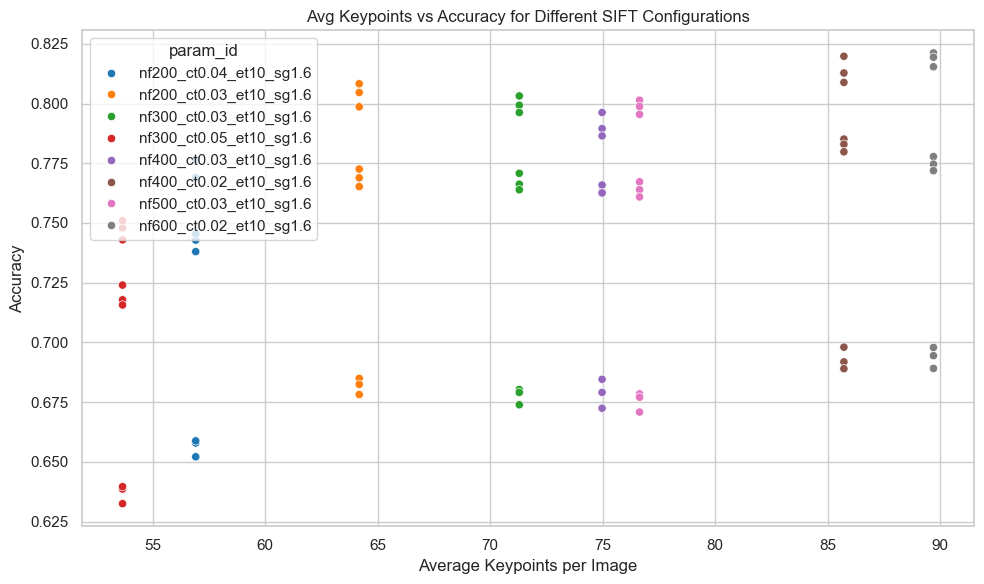

In [23]:
# Plot 3: Avg Keypoints vs Accuracy
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x="avg_keypoints", y="accuracy", hue="param_id", palette="tab10")
plt.title("Avg Keypoints vs Accuracy for Different SIFT Configurations")
plt.xlabel("Average Keypoints per Image")
plt.ylabel("Accuracy")
plt.tight_layout()
plt.savefig("figure_3_accuracy_vs_keypoints_2.png")
plt.show()

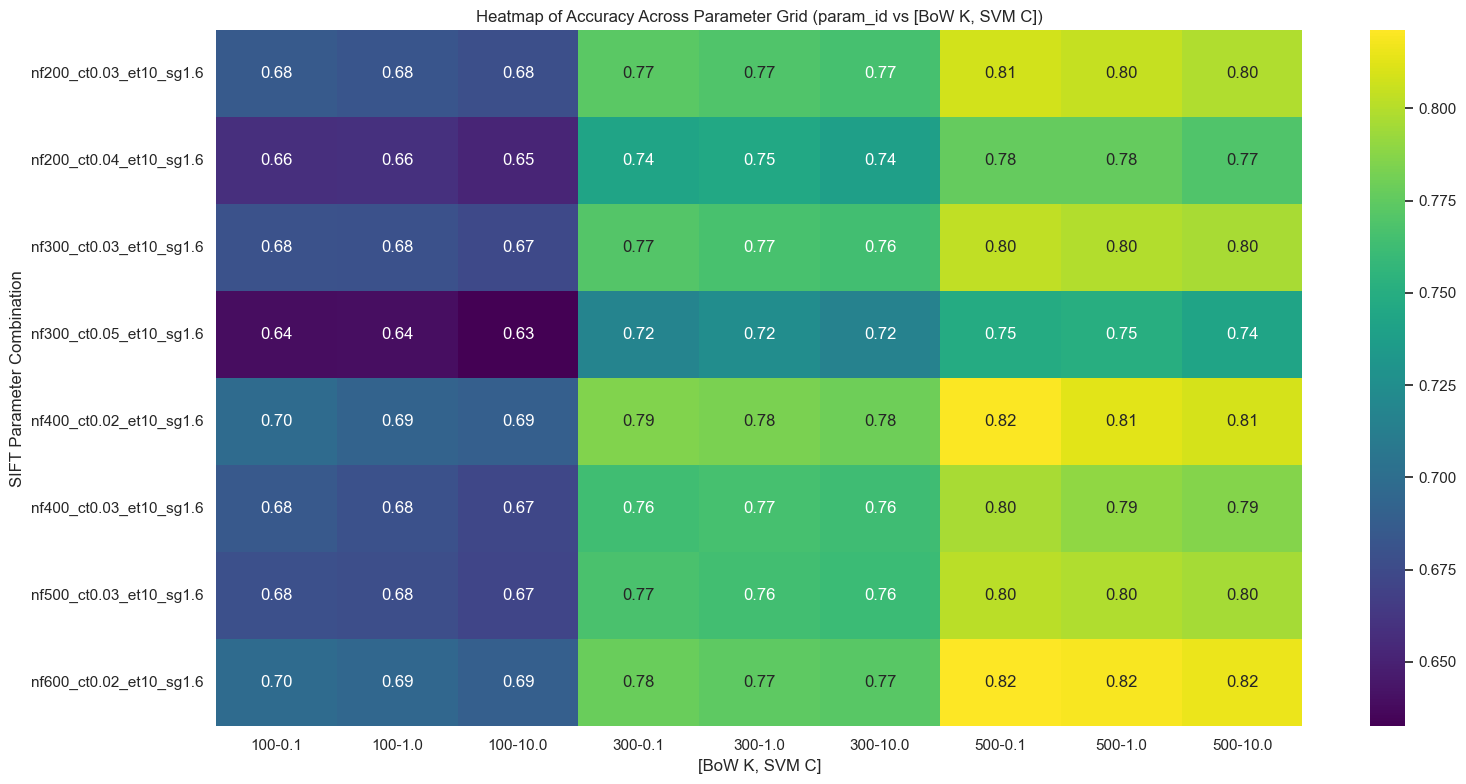

All result files saved (CSV + Excel + heatmap figure)


In [24]:
# Plot 4: Heatmap of accuracy by param_id × (bow_k, svm_C)
pivot_table = df_results.pivot_table(index="param_id", columns=["bow_k", "svm_C"], values="accuracy")

# Plot and save heatmap
plt.figure(figsize=(16, 8))
sns.heatmap(pivot_table, annot=True, fmt=".2f", cmap="viridis")
plt.title("Heatmap of Accuracy Across Parameter Grid (param_id vs [BoW K, SVM C])")
plt.xlabel("[BoW K, SVM C]")
plt.ylabel("SIFT Parameter Combination")
plt.tight_layout()
plt.savefig("figure_4_heatmap_accuracy_2.png")
plt.show()

# Save raw results as CSV (safe)
df_results.to_csv("all_accuracy_results_2.csv", index=False)

# Save pivot table as CSV (safe)
pivot_table.to_csv("accuracy_comparison_table_2.csv")  # MultiIndex columns are OK in CSV

# Save Excel version — flatten columns first
pivot_table_excel = pivot_table.copy()
pivot_table_excel.columns = [f"BoW_{k}__C_{c}" for (k, c) in pivot_table_excel.columns]
pivot_table_excel.reset_index().to_excel("accuracy_comparison_table_2.xlsx", sheet_name="Pivot Table", index=False)

print("All result files saved (CSV + Excel + heatmap figure)")

Extracting SIFT: {'nfeatures': 600, 'contrastThreshold': 0.02, 'edgeThreshold': 10, 'sigma': 1.6}: 100%|█| 60000/60000 
[local path]/_kmeans.py:1955: UserWarning: MiniBatchKMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can prevent it by setting batch_size >= 3584 or by setting the environment variable OMP_NUM_THREADS=4
  warnings.warn(


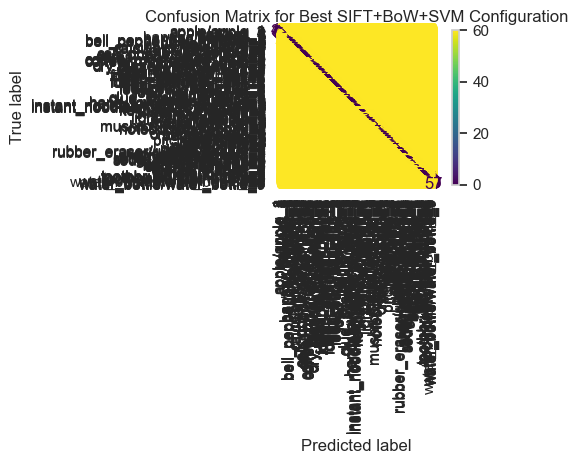

In [37]:
# Confusion Matrix & Per-Class Accuracy
# Step 1: Select the best configuration (highest accuracy)
best_row = df.sort_values(by="accuracy", ascending=False).iloc[0]

# Step 2: Extract parameters from best-performing row
best_param_id = best_row["param_id"]
best_k = best_row["bow_k"]
best_c = best_row["svm_C"]

# Step 3: Create SIFT config dictionary
best_params = {
    "nfeatures": best_row["nfeatures"],
    "contrastThreshold": best_row["contrastThreshold"],
    "edgeThreshold": best_row["edgeThreshold"],
    "sigma": best_row["sigma"]
}

# Step 4: Extract SIFT descriptors
des_list, _, _ = extract_sift_descriptors_and_stats(sampled_image_paths, best_params)

# Step 5: Compute BoW features and train/test split
X = compute_bow_histograms(des_list, best_k)
y = np.array(sampled_labels)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify=y, random_state=42)

# Step 6: Train SVM classifier
clf = SVC(kernel='linear', C=best_c, random_state=42)
clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)

# Step 7: Per-class metrics
class_precision, class_recall, class_f1, _ = precision_recall_fscore_support(y_test, y_pred, zero_division=0)
class_names = [label_map[i] for i in sorted(set(y_test))]

# Step 8: Build DataFrame for analysis
df_acc = pd.DataFrame({
    "class_name": class_names,
    "recall": class_recall
}).sort_values(by="recall", ascending=False)


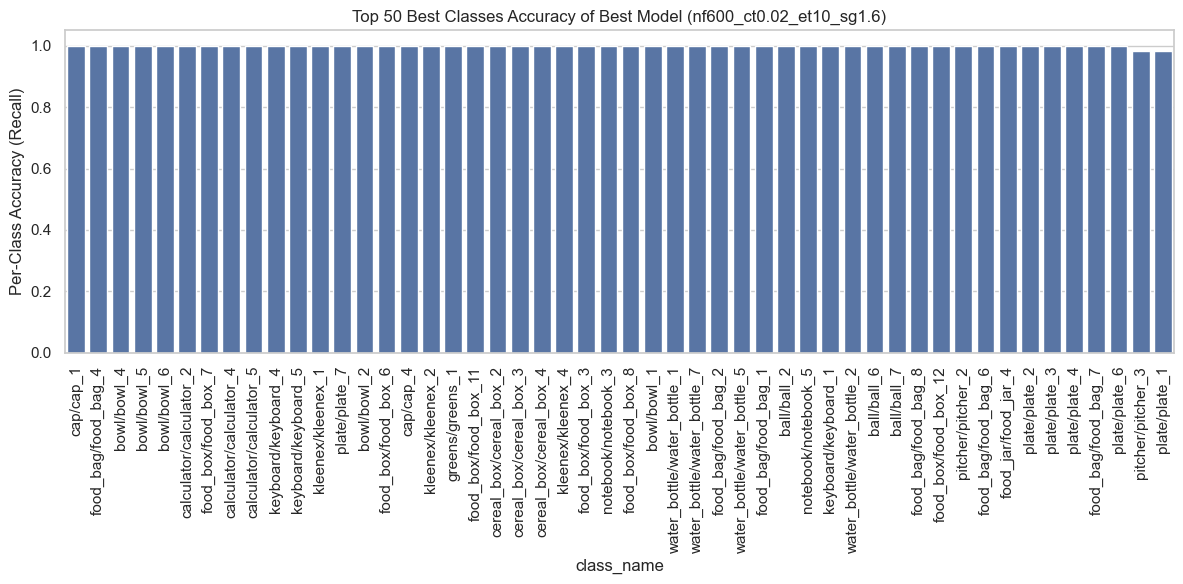

In [38]:
# Plot Top 50 highest recall
plt.figure(figsize=(12, 6))
sns.barplot(data=df_acc.head(50), x="class_name", y="recall")
plt.xticks(rotation=90)
plt.ylim(0, 1.05)
plt.ylabel("Per-Class Accuracy (Recall)")
plt.title(f"Top 50 Best Classes Accuracy of Best Model ({best_param_id})")
plt.tight_layout()
plt.savefig("figure_5_top50_highest_accuracy_2.png")
plt.show()

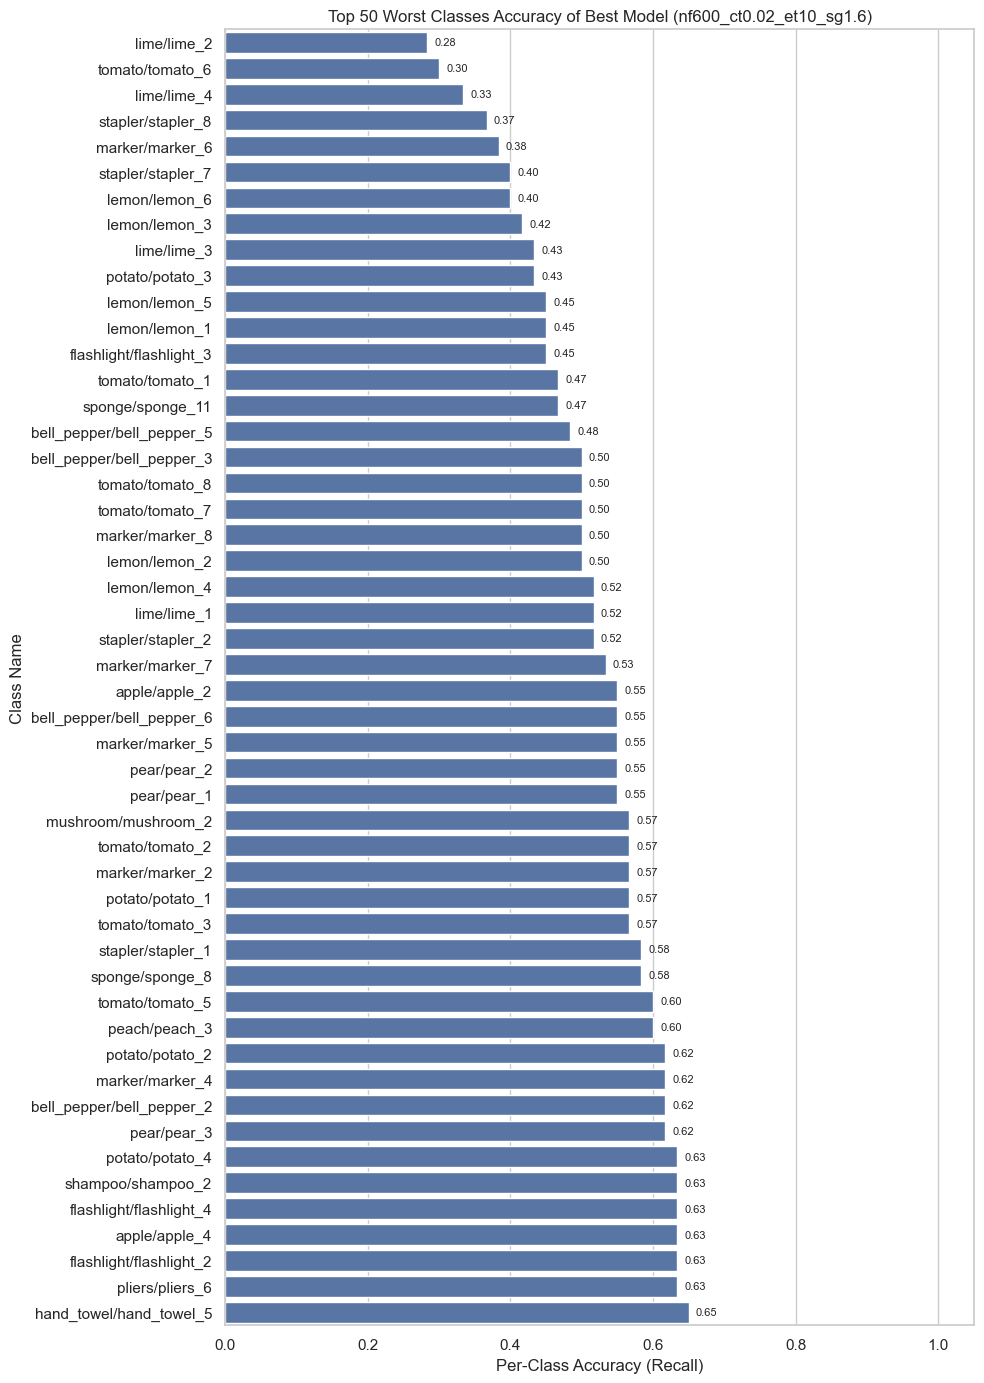

In [39]:
# Plot Top 50 lowest recall — Vertical with value labels
df_bottom50 = df_acc.tail(50).sort_values(by="recall", ascending=True)

plt.figure(figsize=(10, 14))  # 加高图像
barplot = sns.barplot(data=df_bottom50, y="class_name", x="recall")

# 添加数值标签
for i, (recall, name) in enumerate(zip(df_bottom50["recall"], df_bottom50["class_name"])):
    plt.text(recall + 0.01, i, f"{recall:.2f}", va="center", fontsize=8)

plt.xlim(0, 1.05)
plt.xlabel("Per-Class Accuracy (Recall)")
plt.ylabel("Class Name")
plt.title(f"Top 50 Worst Classes Accuracy of Best Model ({best_param_id})")
plt.tight_layout()
plt.savefig("figure_6_top50_lowest_accuracy_vertical_labeled_2.png")
plt.show()

In [43]:
from collections import defaultdict

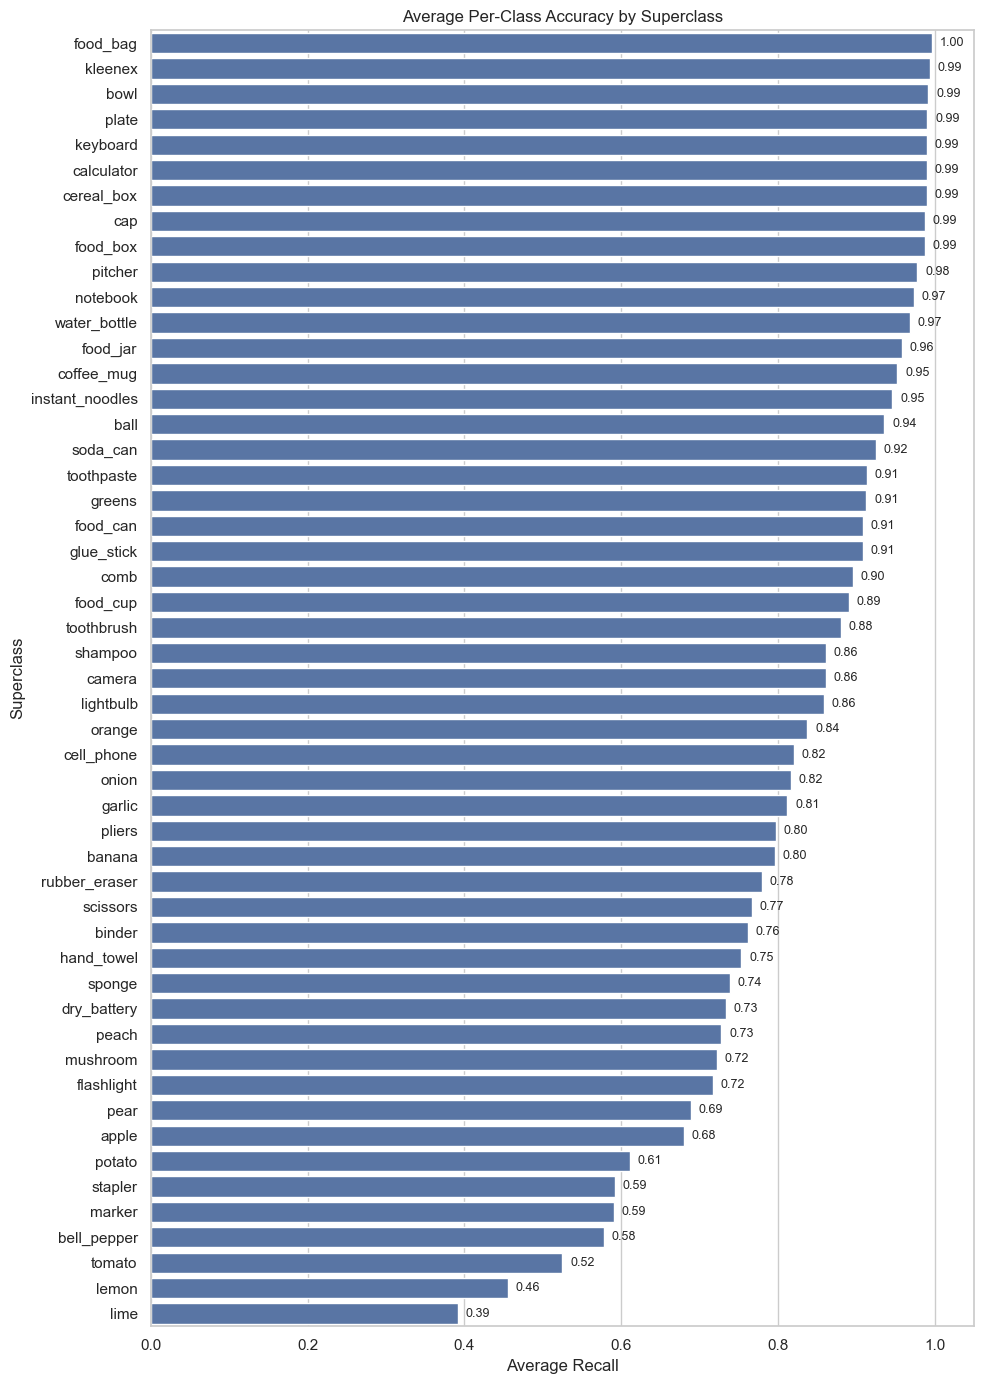

In [45]:
# 建立小类 → 大类映射
small_class_to_superclass = {
    i: label_map[i].split("/")[0] for i in range(len(label_map))
}

# 计算每个大类的平均 recall
super_recall = defaultdict(list)
for i, rec in enumerate(class_recall):
    superclass = small_class_to_superclass[i]
    super_recall[superclass].append(rec)

super_avg = {k: np.mean(v) for k, v in super_recall.items()}
df_super = pd.DataFrame({
    "superclass": list(super_avg.keys()),
    "avg_recall": list(super_avg.values())
}).sort_values(by="avg_recall", ascending=False)

# 竖向绘图
plt.figure(figsize=(10, 14))
barplot = sns.barplot(data=df_super, y="superclass", x="avg_recall")

# 在每个柱子右边加上数值
for i, (recall, cat) in enumerate(zip(df_super["avg_recall"], df_super["superclass"])):
    plt.text(recall + 0.01, i, f"{recall:.2f}", va="center", fontsize=9)

plt.xlim(0, 1.05)
plt.xlabel("Average Recall")
plt.ylabel("Superclass")
plt.title("Average Per-Class Accuracy by Superclass")
plt.tight_layout()
plt.savefig("figure_7_superclass_avg_accuracy_vertical_labeled_2.png")
plt.show()

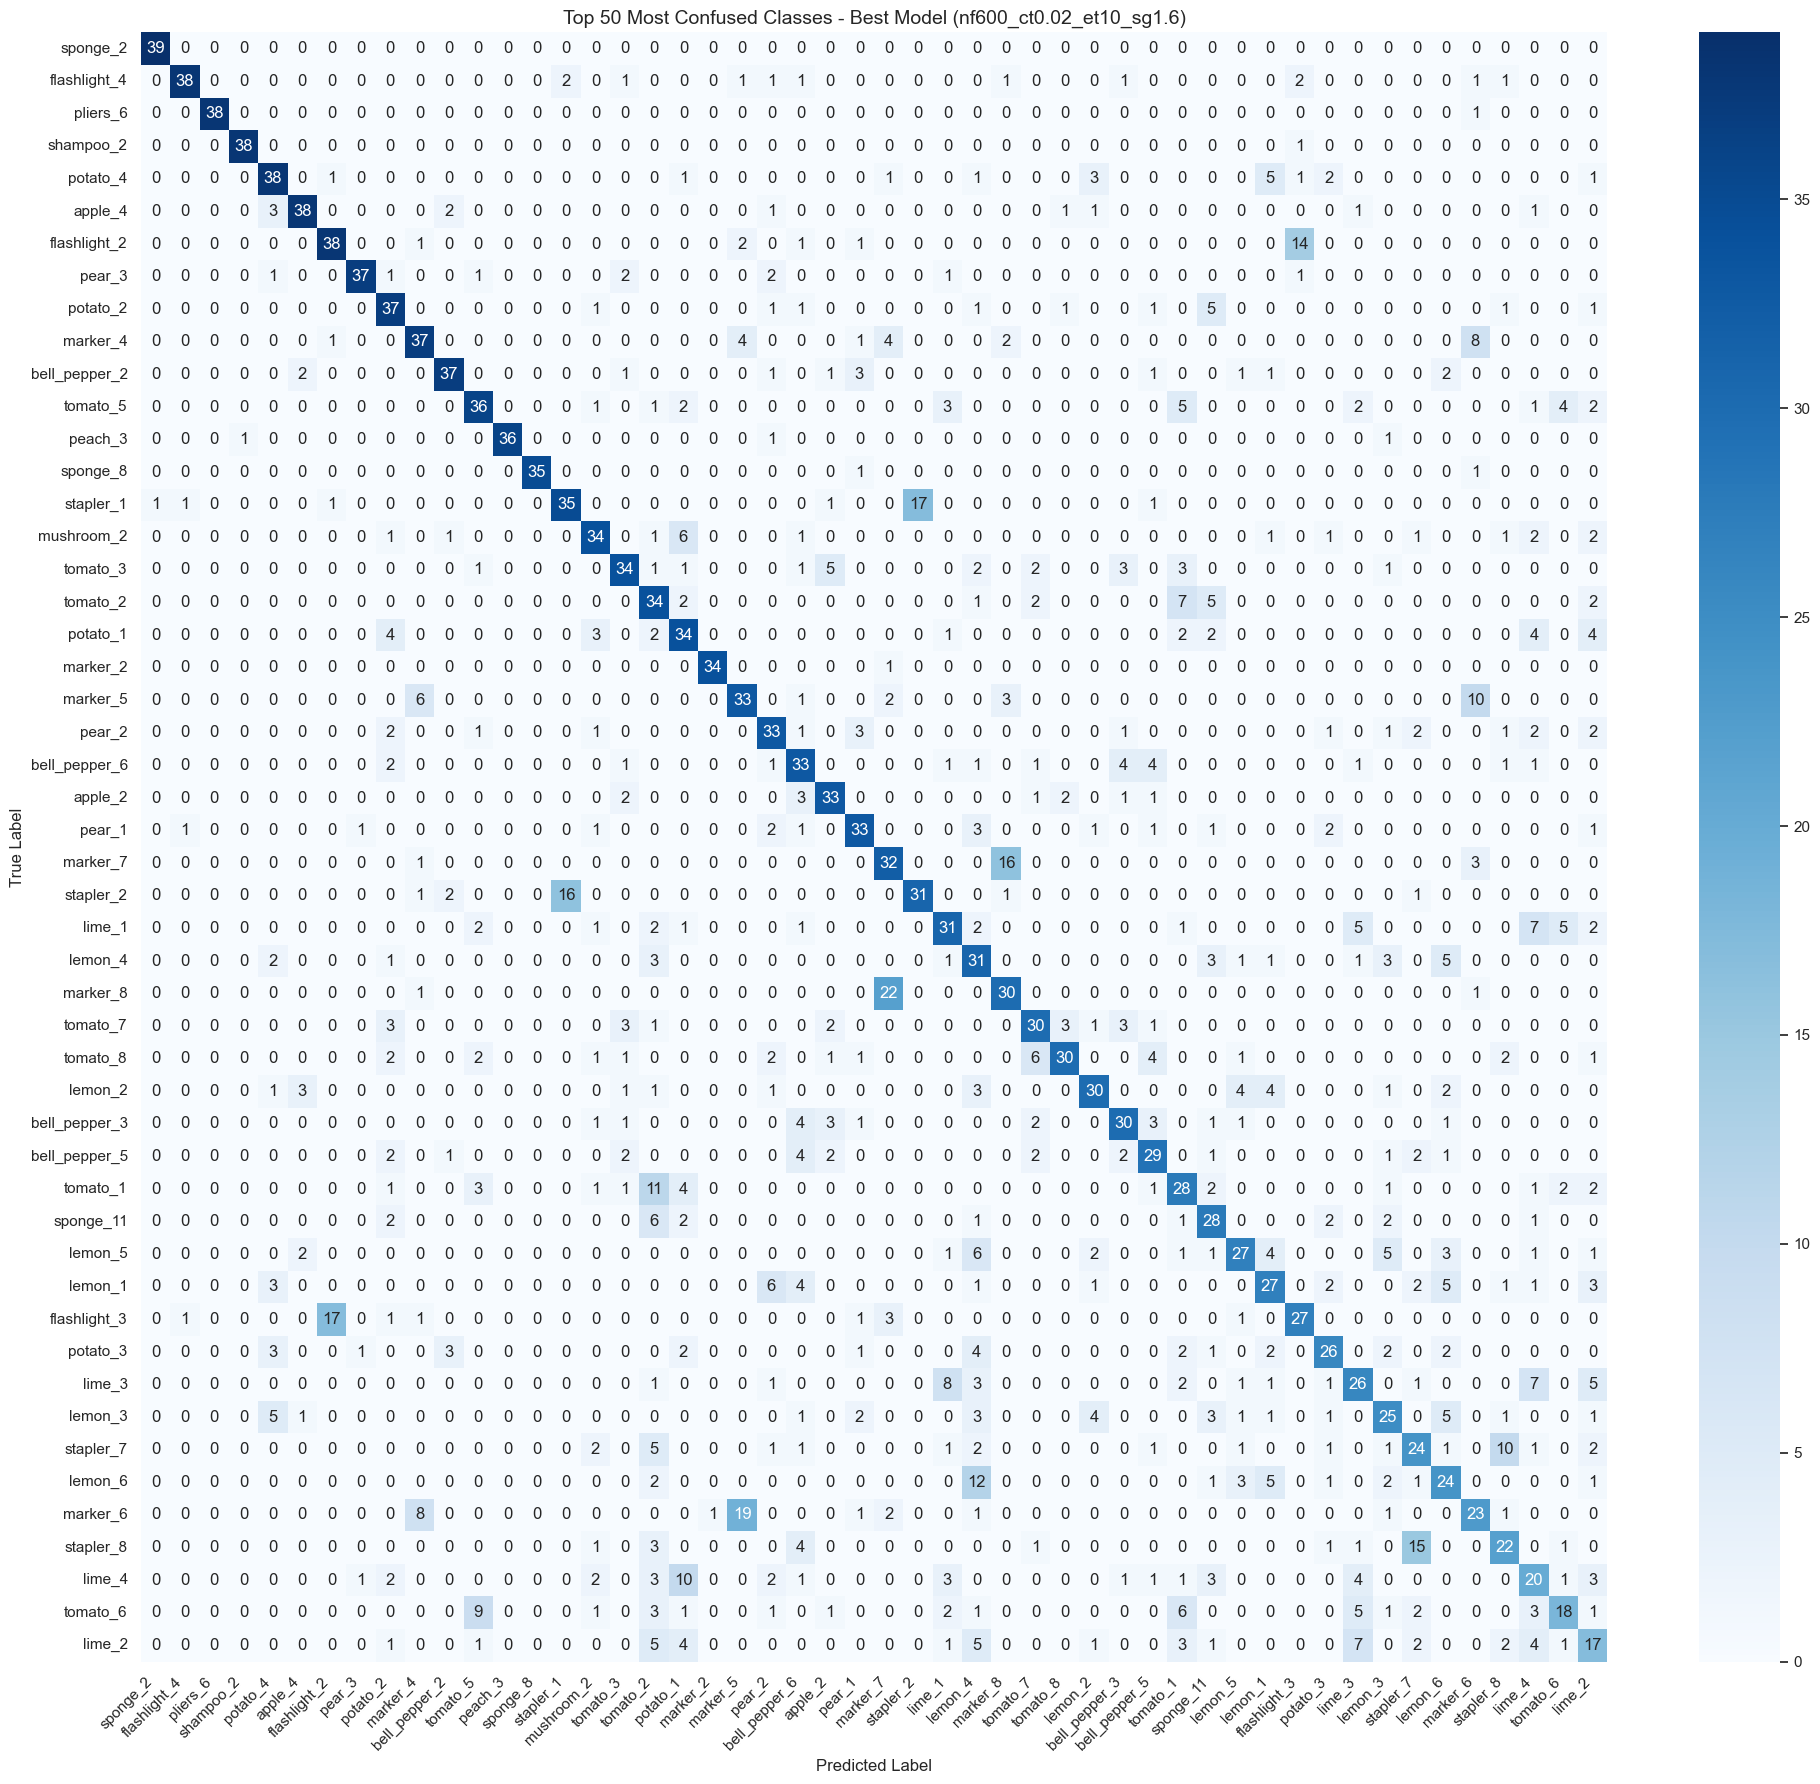

In [47]:
# Plot 6: Confusion Matrix (Top 50 most confused classes)
cm = confusion_matrix(y_test, y_pred)
cm_sum = cm.sum(axis=1) - np.diag(cm)  # off-diagonal sum = confusion
top50_confused_idx = np.argsort(cm_sum)[-50:]  # most confused classes

# 重新生成 confusion matrix 和子类名
cm = confusion_matrix(y_test, y_pred)
cm_sum = cm.sum(axis=1) - np.diag(cm)
top50_idx = np.argsort(cm_sum)[-50:]

cm_top50 = cm[np.ix_(top50_idx, top50_idx)]
short_labels = [class_names[i].split("/")[-1] for i in top50_idx]

# 可视化优化版本
plt.figure(figsize=(20, 18))
sns.heatmap(cm_top50, annot=True, fmt="d", cmap="Blues", xticklabels=short_labels, yticklabels=short_labels, cbar=True)

plt.title(f"Top 50 Most Confused Classes - Best Model ({best_param_id})", fontsize=14)
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.savefig("figure_6_confusion_matrix_top50_optimized_2.png")
plt.show()

# Export classification report as CSV 
report = classification_report(y_test, y_pred, target_names=class_names, output_dict=True)
report_df = pd.DataFrame(report).transpose()
report_df.to_csv("classification_report_best_model_2.csv", index=True)

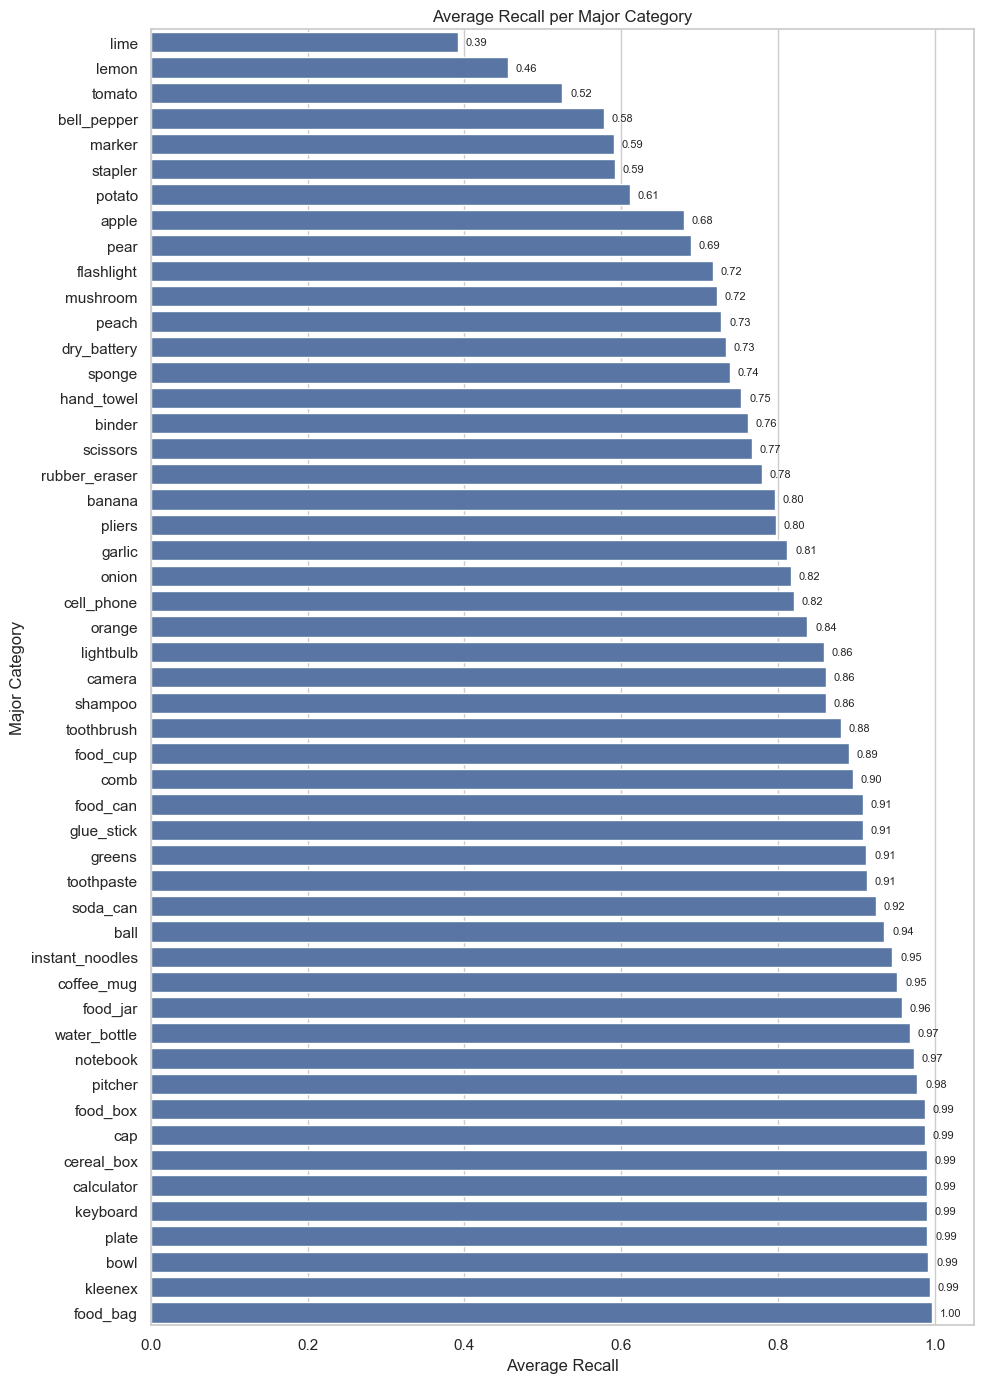

All evaluation complete. Optimized confusion matrix and category-level recall plot saved.


In [49]:
# Grouped average recall (assuming big_class_map is defined)
from collections import defaultdict
recall_array = report_df.loc[class_names, "recall"].values

big_class_recalls = defaultdict(list)
for i, class_name in enumerate(class_names):
    big_class = class_name.split("/")[0]
    big_class_recalls[big_class].append(recall_array[i])
# 计算平均值
avg_recalls = {k: np.mean(v) for k, v in big_class_recalls.items()}

# 转为 DataFrame 并排序
df_avg = pd.DataFrame({
    "category": list(avg_recalls.keys()),
    "avg_recall": list(avg_recalls.values())
}).sort_values(by="avg_recall", ascending=True)

# 绘图
plt.figure(figsize=(10, 14))  # 加高适应标签
ax = sns.barplot(data=df_avg, y="category", x="avg_recall")

# 添加数值标签
for i, (recall, cat) in enumerate(zip(df_avg["avg_recall"], df_avg["category"])):
    plt.text(recall + 0.01, i, f"{recall:.2f}", va="center", fontsize=8)

plt.xlim(0, 1.05)
plt.xlabel("Average Recall")
plt.ylabel("Major Category")
plt.title("Average Recall per Major Category")
plt.tight_layout()
plt.savefig("figure_grouped_average_recall_horizontal_labeled_2.png")
plt.show()

print("All evaluation complete. Optimized confusion matrix and category-level recall plot saved.")

In [ ]:
# Plot 6: Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(12, 10))
cmd = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
cmd.plot(cmap="Blues", xticks_rotation=90)
plt.title(f"Confusion Matrix - Best Model ({best_param_id})")
plt.tight_layout()
plt.savefig("figure_6_confusion_matrix_2.png")
plt.show()

# Export classification report as CSV 
report = classification_report(y_test, y_pred, target_names=class_names, output_dict=True)
report_df = pd.DataFrame(report).transpose()
report_df.to_csv("classification_report_best_model_2.csv", index=True)

In [ ]:
# Additional Visualizations
# Convert recall to array and sort
recall_array = report_df.loc[class_names, "recall"].values

# Top 50 highest recall
sorted_high_idx = np.argsort(recall_array)[-50:]
plt.figure(figsize=(12, 6))
sns.barplot(x=[class_names[i] for i in sorted_high_idx], y=recall_array[sorted_high_idx])
plt.xticks(rotation=90)
plt.title("Top 50 Classes with Highest Recall")
plt.ylabel("Recall")
plt.tight_layout()
plt.savefig("figure_top50_high_recall_2.png")
plt.show()

In [ ]:
# Top 50 lowest recall
sorted_low_idx = np.argsort(recall_array)[:50]
plt.figure(figsize=(12, 6))
sns.barplot(x=[class_names[i] for i in sorted_low_idx], y=recall_array[sorted_low_idx])
plt.xticks(rotation=90)
plt.title("Top 50 Classes with Lowest Recall")
plt.ylabel("Recall")
plt.tight_layout()
plt.savefig("figure_top50_low_recall_2.png")
plt.show()

In [ ]:
# Grouped average recall (assuming big_class_map is defined)
from collections import defaultdict
big_class_recalls = defaultdict(list)

for i, class_name in enumerate(class_names):
    big_class = big_class_map.get(i, "Unknown")
    big_class_recalls[big_class].append(recall_array[i])

avg_recalls = {k: np.mean(v) for k, v in big_class_recalls.items()}
plt.figure(figsize=(12, 6))
sns.barplot(x=list(avg_recalls.keys()), y=list(avg_recalls.values()))
plt.xticks(rotation=45)
plt.title("Average Recall per Major Category")
plt.ylabel("Average Recall")
plt.tight_layout()
plt.savefig("figure_grouped_average_recall_2.png")
plt.show()

print("All evaluation complete. Confusion matrix, classification report, and detailed recall plots saved.")


In [ ]:
# ============================
# FINAL EVALUATION OF BEST MODEL
# This section:
# 1. Automatically selects the best-performing model from all experiments.
# 2. Reconstructs the model with its optimal SIFT + BoW + SVM parameters.
# 3. Evaluates performance:
#    - Confusion Matrix
#    - Top 50 High & Low Recall Classes
#    - Average Recall by 51 Major Categories
# 4. Exports all visualizations and reports
# ============================

In [ ]:
# Confusion Matrix & Per-Class Accuracy
# The group with the highest accuracy
best_row = df.sort_values(by="accuracy", ascending=False).iloc[0]

# Extract the best parameters from the top-performing row
best_param_id = best_row["param_id"]
best_k = best_row["bow_k"]
best_c = best_row["svm_C"]

# Construct the full SIFT parameter dictionary for the best config
best_params = {
    "nfeatures": best_row["nfeatures"],
    "contrastThreshold": best_row["contrastThreshold"],
    "edgeThreshold": best_row["edgeThreshold"],
    "sigma": best_row["sigma"]
}
des_list = extract_sift_descriptors(image_paths, best_params)
X = compute_bow(des_list, best_k)
y = np.array(labels)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify=y, random_state=42)

clf = SVC(kernel='linear', C=best_c, random_state=42)
clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)

# Per-Class Accuracy
class_precision, class_recall, class_f1, _ = precision_recall_fscore_support(y_test, y_pred, zero_division=0)
class_names = [label_map[i] for i in sorted(set(y_test))]

plt.figure(figsize=(12, 6))
sns.barplot(x=class_names, y=class_recall)
plt.xticks(rotation=90)
plt.ylabel("Per-Class Accuracy (Recall)")
plt.title(f"Per-Class Accuracy of Best Model ({best_param_id})")
plt.tight_layout()
plt.savefig("figure_5_per_class_accuracy_2.png")
plt.show()

In [ ]:
# Plot 6: Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(12, 10))
cmd = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
cmd.plot(cmap="Blues", xticks_rotation=90)
plt.title(f"Confusion Matrix - Best Model ({best_param_id})")
plt.tight_layout()
plt.savefig("figure_6_confusion_matrix_2.png")
plt.show()
# Export classification report as CSV 
# Compute per-class metrics: precision, recall, f1-score, and support
report = classification_report(y_test, y_pred, target_names=class_names, output_dict=True)

# Convert to DataFrame and save as CSV (safer than Excel)
report_df = pd.DataFrame(report).transpose()
report_df.to_csv("classification_report_best_model_2.csv", index=True)

print("All evaluation complete. Confusion matrix and classification report saved.")